## Setup Dependencies
Install required packages. Output is captured to keep Kaggle logs clean.


In [1]:
# import kagglehub

# Download latest version
# path = kagglehub.dataset_download("mouryavardhanrathod/nhd-dataset-v1")

# print("Path to dataset files:", path)

In [2]:
%%capture
# Kaggle dependencies for the physics beta pipeline and RESIDE-style MHCAFNet++ dehazer
!pip -q install timm torchmetrics lpips torchsummary --root-user-action=ignore


## Depth Anything V2 Setup
Install Depth Anything V2 and download the ViT-S checkpoint used to estimate depth for every hazy image. The `xFormers not available` message is harmless; Depth Anything falls back to standard attention.


In [3]:
%%capture
# Install Depth Anything V2 and download the ViT-S checkpoint for depth estimation.
import os

DEPTH_ANYTHING_DIR = "/kaggle/working/Depth-Anything-V2"
if not os.path.isdir(DEPTH_ANYTHING_DIR):
    !git clone https://github.com/DepthAnything/Depth-Anything-V2.git /kaggle/working/Depth-Anything-V2

%cd /kaggle/working/Depth-Anything-V2
!pip install -q -r requirements.txt --root-user-action=ignore
!mkdir -p checkpoints
!wget -q -O checkpoints/depth_anything_v2_vits.pth https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth


## Imports and Warning Control
Import all libraries and suppress harmless warnings that previously cluttered the notebook output.


In [4]:
import os
import json
import pickle
import random
import warnings
from dataclasses import dataclass

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import normalize
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from scipy.stats import pearsonr, ConstantInputWarning, NearConstantInputWarning
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchmetrics.image import PeakSignalNoiseRatio, StructuralSimilarityIndexMeasure
from tqdm.auto import tqdm
import pandas as pd
import lpips

try:
    import timm
except ImportError as exc:
    raise ImportError("Install timm in Kaggle first: !pip -q install timm") from exc

# Clean notebook output: keep model metrics visible and hide harmless library warnings.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="torchvision")
warnings.filterwarnings("ignore", category=ConstantInputWarning)
warnings.filterwarnings("ignore", category=NearConstantInputWarning)


## Configuration
Use the better v3 setup with selected haze strategies, sharper retrieval, larger codebook, and depth-conditioned residual refinement.


In [5]:
@dataclass
class CFG:
    # Change this if your Kaggle input mount is different.
    ROOT: str = "/kaggle/input/datasets/mouryavardhanrathod/nhd-dataset-v1/NHD"
    INDEX_FILE: str = ""

    IMAGE_SIZE: int = 224
    PATCH_SIZE: int = 16
    GRID: int = 14  # ViT token grid for 224x224 / 16x16 patches
    BETA_GRID: int = 56  # high-resolution beta map; use 112 if GPU memory allows
    EMBED_DIM: int = 384
    BETA_MIN: float = 0.02
    BETA_MAX: float = 2.0

    BATCH_SIZE: int = 8
    DEHAZE_IMAGE_SIZE: int = 256
    DEHAZE_BATCH_SIZE: int = 8
    DEHAZE_EPOCHS: int = 150
    DEHAZE_LR: float = 1e-4
    DEHAZE_PATIENCE: int = 5
    NUM_WORKERS: int = 0
    SEED: int = 42

    # Focus on the haze-generation regimes used for the main experiment.
    # Excluding inverse_depth and beta_only_variation reduces conflicting beta rules.
    SELECTED_STRATEGIES: tuple = (
        "uniform",
        "fog_bank",
        "perlin",
        "radial",
        "depth_dep",
    )

    PRETRAIN_EPOCHS: int = 150
    PRETRAIN_LR: float = 1e-4
    PRETRAIN_PATIENCE: int = 8

    K: int = 512
    KMEANS_BATCH: int = 4096
    RETRIEVAL_TAU: float = 0.03

    REFINE_EPOCHS: int = 150
    REFINE_LR: float = 3e-4
    REFINE_PATIENCE: int = 10
    MAX_DELTA_BETA: float = 0.08

    JOINT_EPOCHS: int = 150
    JOINT_LR: float = 2e-4
    JOINT_PATIENCE: int = 8
    A_LOSS_WEIGHT: float = 0.2
    PHYSICS_LOSS_WEIGHT: float = 0.3
    FINAL_LOSS_WEIGHT: float = 1.0

    OUT_DIR: str = "/kaggle/working/physics_graded_dehaze"


cfg = CFG()
cfg.INDEX_FILE = os.path.join(cfg.ROOT, "dataset_index.json")
os.makedirs(cfg.OUT_DIR, exist_ok=True)


def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


set_seed(cfg.SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Output dir:", cfg.OUT_DIR)


Device: cuda
Output dir: /kaggle/working/physics_graded_dehaze


## Depth Anything V2 Depth Function
Predict a depth map from each hazy RGB image and resize it to the high-resolution beta grid (`cfg.BETA_GRID x cfg.BETA_GRID`).


In [6]:
from depth_anything_v2.dpt import DepthAnythingV2

depth_model_config = {
    "encoder": "vits",
    "features": 64,
    "out_channels": [48, 96, 192, 384],
}

depth_model = DepthAnythingV2(**depth_model_config)
depth_model.load_state_dict(
    torch.load(
        "/kaggle/working/Depth-Anything-V2/checkpoints/depth_anything_v2_vits.pth",
        map_location=device,
    )
)
depth_model = depth_model.to(device)
depth_model.eval()


def estimate_depth(rgb):
    """
    rgb: H x W x 3 float image in range [0, 1].
    Returns a normalized cfg.BETA_GRID x cfg.BETA_GRID depth map.
    """
    image = (np.clip(rgb, 0.0, 1.0) * 255).astype(np.uint8)

    with torch.no_grad():
        depth = depth_model.infer_image(image)

    depth = cv2.resize(
        depth,
        (cfg.BETA_GRID, cfg.BETA_GRID),
        interpolation=cv2.INTER_AREA,
    )
    depth = depth.astype(np.float32)
    depth = (depth - depth.min()) / (depth.max() - depth.min() + 1e-8)
    return depth


def estimate_depth_tensor_from_hazy_vis(hazy_vis):
    hazy_np = hazy_vis.permute(1, 2, 0).detach().cpu().numpy()
    depth = estimate_depth(hazy_np)
    return torch.from_numpy(depth).unsqueeze(0).unsqueeze(0).to(device)


def estimate_depth_batch(hazy_vis_batch):
    depths = []
    for hazy_vis in hazy_vis_batch:
        hazy_np = hazy_vis.permute(1, 2, 0).detach().cpu().numpy()
        depths.append(estimate_depth(hazy_np))
    return torch.from_numpy(np.stack(depths)).unsqueeze(1).to(device)


print(f"Depth Anything V2 loaded; depth maps resize to {cfg.BETA_GRID}x{cfg.BETA_GRID}.")


xFormers not available
xFormers not available


Depth Anything V2 loaded; depth maps resize to 56x56.


## NHD Dataset Loader
Load only the selected strategies: `uniform`, `fog_bank`, `perlin`, `radial`, and `depth_dep`. This avoids mixing in beta rules that made the weaker version unstable.


In [7]:
image_transform = transforms.Compose([
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225),
    ),
])

vis_transform = transforms.Compose([
    transforms.Resize((cfg.IMAGE_SIZE, cfg.IMAGE_SIZE)),
    transforms.ToTensor(),
])

dehaze_transform = transforms.Compose([
    transforms.Resize((cfg.DEHAZE_IMAGE_SIZE, cfg.DEHAZE_IMAGE_SIZE)),
    transforms.ToTensor(),
])

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")


def resize_map(x, size=(14, 14)):
    return cv2.resize(x.astype(np.float32), size, interpolation=cv2.INTER_AREA)


def read_npz_key(path, candidates):
    data = np.load(path)
    for key in candidates:
        if key in data:
            return data[key]
    raise KeyError(f"{path} does not contain any of: {candidates}")


with open(cfg.INDEX_FILE, "r") as f:
    metadata = json.load(f)


def build_pairs(split):
    pairs = []
    for item in metadata:
        if item.get("split") != split:
            continue
        if item.get("strategy") not in cfg.SELECTED_STRATEGIES:
            continue

        pair = {
            "dataset": "NHD_dataset",
            "img_id": item.get("img_id", ""),
            "strategy": item.get("strategy", ""),
            "A": item["A"],
            "hazy": os.path.join(cfg.ROOT, item["hazy_path"]),
            "gt": os.path.join(cfg.ROOT, item["gt_path"]),
            "beta": os.path.join(cfg.ROOT, item["beta_path"]),
            "depth": os.path.join(cfg.ROOT, item["depth_path"]),
            "trans": os.path.join(cfg.ROOT, item["trans_path"]),
        }

        if all(os.path.exists(pair[k]) for k in ["hazy", "gt", "beta", "depth", "trans"]):
            pairs.append(pair)
    return pairs


def estimate_atmospheric_light(rgb, top_percent=0.001):
    flat = rgb.reshape(-1, 3).astype(np.float32)
    scores = flat.mean(axis=1)
    k = max(1, int(len(scores) * top_percent))
    idx = np.argpartition(scores, -k)[-k:]
    return flat[idx].mean(axis=0).astype(np.float32)


def normalize_pair_stem(path):
    stem = os.path.splitext(os.path.basename(path))[0].lower()
    for token in ["_hazy", "-hazy", " haze", "_gt", "-gt", "_clean", "-clean", "_clear", "-clear"]:
        stem = stem.replace(token, "")
    return stem


def list_images(folder):
    if not folder or not os.path.isdir(folder):
        return []
    paths = []
    for root, _, files in os.walk(folder):
        for name in files:
            if name.lower().endswith(IMAGE_EXTENSIONS):
                paths.append(os.path.join(root, name))
    return sorted(paths)


def build_image_pairs_from_folders(hazy_dir, gt_dir):
    hazy_paths = list_images(hazy_dir)
    gt_paths = list_images(gt_dir)
    gt_by_stem = {normalize_pair_stem(path): path for path in gt_paths}

    pairs = []
    used_gt = set()
    for hazy_path in hazy_paths:
        key = normalize_pair_stem(hazy_path)
        gt_path = gt_by_stem.get(key)
        if gt_path is not None:
            pairs.append((hazy_path, gt_path))
            used_gt.add(gt_path)

    if not pairs and len(hazy_paths) == len(gt_paths):
        pairs = list(zip(hazy_paths, gt_paths))
    return pairs


def find_existing_test_folder(candidates):
    for folder in candidates:
        if os.path.isdir(os.path.join(folder, "hazy")) and os.path.isdir(os.path.join(folder, "gt")):
            return folder
    return None


class NHDPhysicsDataset(Dataset):
    def __init__(self, pairs):
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        item = self.pairs[idx]

        hazy_img = Image.open(item["hazy"]).convert("RGB")
        gt_img = Image.open(item["gt"]).convert("RGB")

        beta = read_npz_key(item["beta"], ["beta", "arr_0"])
        depth = read_npz_key(item["depth"], ["depth", "arr_0"])
        trans = read_npz_key(item["trans"], ["transmission", "trans", "arr_0"])

        beta = resize_map(beta, (cfg.BETA_GRID, cfg.BETA_GRID))
        depth = resize_map(depth, (cfg.BETA_GRID, cfg.BETA_GRID))
        trans = resize_map(trans, (cfg.BETA_GRID, cfg.BETA_GRID))

        A = np.asarray(item["A"], dtype=np.float32)
        if A.max() > 1.5:
            A = A / 255.0

        return {
            "hazy": image_transform(hazy_img),
            "hazy_vis": vis_transform(hazy_img),
            "gt": vis_transform(gt_img),
            "hazy_dehaze": dehaze_transform(hazy_img),
            "gt_dehaze": dehaze_transform(gt_img),
            "beta": torch.tensor(beta, dtype=torch.float32),
            "depth": torch.tensor(depth, dtype=torch.float32),
            "trans": torch.tensor(trans, dtype=torch.float32),
            "A": torch.tensor(A, dtype=torch.float32),
            "has_beta": True,
            "dataset": item.get("dataset", "NHD_dataset"),
            "img_id": item["img_id"],
            "strategy": item["strategy"],
        }


class PairedHazyGTDataset(Dataset):
    def __init__(self, dataset_name, test_root):
        self.dataset_name = dataset_name
        self.test_root = test_root
        self.pairs = build_image_pairs_from_folders(
            os.path.join(test_root, "hazy"),
            os.path.join(test_root, "gt"),
        )

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        hazy_path, gt_path = self.pairs[idx]
        hazy_img = Image.open(hazy_path).convert("RGB")
        gt_img = Image.open(gt_path).convert("RGB")
        hazy_vis = vis_transform(hazy_img)
        hazy_np = hazy_vis.permute(1, 2, 0).numpy()
        A = estimate_atmospheric_light(hazy_np)

        return {
            "hazy": image_transform(hazy_img),
            "hazy_vis": hazy_vis,
            "gt": vis_transform(gt_img),
            "hazy_dehaze": dehaze_transform(hazy_img),
            "gt_dehaze": dehaze_transform(gt_img),
            "beta": torch.full((cfg.BETA_GRID, cfg.BETA_GRID), float("nan"), dtype=torch.float32),
            "depth": torch.full((cfg.BETA_GRID, cfg.BETA_GRID), float("nan"), dtype=torch.float32),
            "trans": torch.full((cfg.BETA_GRID, cfg.BETA_GRID), float("nan"), dtype=torch.float32),
            "A": torch.tensor(A, dtype=torch.float32),
            "has_beta": False,
            "dataset": self.dataset_name,
            "img_id": os.path.basename(hazy_path),
            "strategy": "real_pair",
        }


train_pairs = build_pairs("train")
val_pairs = build_pairs("val")
test_pairs = build_pairs("test")

print("NHD pairs:", len(train_pairs), len(val_pairs), len(test_pairs))

train_dataset = NHDPhysicsDataset(train_pairs)
val_dataset = NHDPhysicsDataset(val_pairs)
test_dataset = NHDPhysicsDataset(test_pairs)

train_loader = DataLoader(
    train_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=True,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
val_loader = DataLoader(
    val_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)
test_loader = DataLoader(
    test_dataset,
    batch_size=cfg.BATCH_SIZE,
    shuffle=False,
    num_workers=cfg.NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
)


NHD pairs: 555 70 70


## High-Resolution Joint Physics Model
Predict a 56 x 56 beta map, learn atmospheric light `A`, reconstruct the physics dehazed image, and refine it with a dehazing decoder.


In [8]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
        )

    def forward(self, x):
        return self.net(x)


class HighResBetaAEstimator(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        self.encoder = timm.create_model(
            "vit_small_patch16_224.dino",
            pretrained=pretrained,
            num_classes=0,
        )
        self.beta_decoder = nn.Sequential(
            nn.Conv2d(cfg.EMBED_DIM, 256, 3, padding=1),
            nn.GELU(),
            nn.ConvTranspose2d(256, 128, 2, stride=2),  # 14 -> 28
            nn.GELU(),
            nn.Conv2d(128, 128, 3, padding=1),
            nn.GELU(),
            nn.ConvTranspose2d(128, 64, 2, stride=2),  # 28 -> 56
            nn.GELU(),
            nn.Conv2d(64, 32, 3, padding=1),
            nn.GELU(),
            nn.Conv2d(32, 1, 1),
        )
        self.a_head = nn.Sequential(
            nn.LayerNorm(cfg.EMBED_DIM),
            nn.Linear(cfg.EMBED_DIM, 128),
            nn.GELU(),
            nn.Linear(128, 3),
            nn.Sigmoid(),
        )

    def forward_features(self, x):
        tokens = self.encoder.forward_features(x)
        patch_tokens = tokens[:, 1:, :]
        cls_or_global = tokens[:, 0, :] if tokens.ndim == 3 else patch_tokens.mean(dim=1)
        return patch_tokens, cls_or_global

    def forward(self, x):
        patch_tokens, global_token = self.forward_features(x)
        b = x.shape[0]
        feat = patch_tokens.transpose(1, 2).reshape(b, cfg.EMBED_DIM, cfg.GRID, cfg.GRID)
        beta_raw = self.beta_decoder(feat).squeeze(1)
        beta_hat = cfg.BETA_MIN + (cfg.BETA_MAX - cfg.BETA_MIN) * torch.sigmoid(beta_raw)
        A_hat = self.a_head(global_token).clamp(0.0, 1.0)
        return patch_tokens, beta_hat, A_hat


class ResidualDehazeNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.e1 = ConvBlock(3, 48)
        self.e2 = ConvBlock(48, 96)
        self.e3 = ConvBlock(96, 192)
        self.pool = nn.MaxPool2d(2)
        self.up2 = nn.ConvTranspose2d(192, 96, 2, stride=2)
        self.d2 = ConvBlock(192, 96)
        self.up1 = nn.ConvTranspose2d(96, 48, 2, stride=2)
        self.d1 = ConvBlock(96, 48)
        self.out = nn.Conv2d(48, 3, 1)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.pool(e1))
        e3 = self.e3(self.pool(e2))
        y = self.up2(e3)
        y = self.d2(torch.cat([y, e2], dim=1))
        y = self.up1(y)
        y = self.d1(torch.cat([y, e1], dim=1))
        residual = self.out(y)
        return torch.clamp(x - residual, 0.0, 1.0)


class EndToEndPhysicsDehazer(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        self.beta_a = HighResBetaAEstimator(pretrained=pretrained)
        self.dehaze_net = ResidualDehazeNet()

    def physics_dehaze(self, hazy, beta_hat, depth, A_hat):
        if depth.ndim == 3:
            depth = depth.unsqueeze(1)
        beta = beta_hat.unsqueeze(1)
        transmission = torch.exp(-beta * depth).clamp(min=0.02, max=1.0)
        transmission = F.interpolate(
            transmission,
            size=hazy.shape[-2:],
            mode="bilinear",
            align_corners=False,
        )
        A = A_hat.view(A_hat.shape[0], 3, 1, 1)
        clean = (hazy - A) / transmission + A
        return clean.clamp(0.0, 1.0), transmission

    def forward(self, x_norm, depth, hazy_vis=None):
        _, beta_hat, A_hat = self.beta_a(x_norm)
        if hazy_vis is None:
            mean = torch.tensor([0.485, 0.456, 0.406], device=x_norm.device).view(1, 3, 1, 1)
            std = torch.tensor([0.229, 0.224, 0.225], device=x_norm.device).view(1, 3, 1, 1)
            hazy_vis = (x_norm * std + mean).clamp(0.0, 1.0)
        physics_clean, transmission = self.physics_dehaze(hazy_vis, beta_hat, depth, A_hat)
        clean_hat = self.dehaze_net(physics_clean)
        return {
            "beta_ret": beta_hat,
            "beta_hat": beta_hat,
            "A_hat": A_hat,
            "physics_clean": physics_clean,
            "clean_hat": clean_hat,
            "transmission": transmission,
            "delta": torch.zeros_like(beta_hat),
            "weights": None,
        }


class PhysicsReconstruction(nn.Module):
    def forward(self, clean_gt, beta_hat, depth, A):
        if depth.ndim == 3:
            depth = depth.unsqueeze(1)
        beta = beta_hat.unsqueeze(1)
        transmission = torch.exp(-beta * depth).clamp(min=0.02, max=1.0)
        transmission_224 = F.interpolate(
            transmission,
            size=(cfg.IMAGE_SIZE, cfg.IMAGE_SIZE),
            mode="bilinear",
            align_corners=False,
        )
        A = A.view(A.shape[0], 3, 1, 1)
        hazy_recon = clean_gt * transmission_224 + A * (1.0 - transmission_224)
        return hazy_recon, transmission_224


def edge_loss(pred, gt):
    pred_dx = pred[:, :, 1:] - pred[:, :, :-1]
    gt_dx = gt[:, :, 1:] - gt[:, :, :-1]
    pred_dy = pred[:, 1:, :] - pred[:, :-1, :]
    gt_dy = gt[:, 1:, :] - gt[:, :-1, :]
    return F.l1_loss(pred_dx, gt_dx) + F.l1_loss(pred_dy, gt_dy)


def smoothness_loss(beta):
    dx = beta[:, :, 1:] - beta[:, :, :-1]
    dy = beta[:, 1:, :] - beta[:, :-1, :]
    return dx.abs().mean() + dy.abs().mean()


def safe_pearsonr(pred, gt, eps=1e-6):
    pred = np.asarray(pred, dtype=np.float64).reshape(-1)
    gt = np.asarray(gt, dtype=np.float64).reshape(-1)
    if np.std(pred) <= eps or np.std(gt) <= eps:
        return np.nan
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", ConstantInputWarning)
        warnings.simplefilter("ignore", NearConstantInputWarning)
        return pearsonr(pred, gt)[0]


def beta_metrics(pred, gt):
    pred = pred.reshape(-1)
    gt = gt.reshape(-1)
    mae = mean_absolute_error(gt, pred)
    rmse = np.sqrt(mean_squared_error(gt, pred))
    corr = safe_pearsonr(pred, gt)
    r2 = r2_score(gt, pred) if np.var(gt) > 1e-8 else np.nan
    return mae, rmse, corr, r2


## End-to-End Joint Training
Train beta prediction, learned atmospheric light, physics reconstruction, and final dehazing together with one combined loss.


In [9]:
model = EndToEndPhysicsDehazer(pretrained=True).to(device)
dehaze_model = model.dehaze_net
physics_module = PhysicsReconstruction().to(device)

psnr_metric = PeakSignalNoiseRatio(data_range=1.0).to(device)
ssim_metric = StructuralSimilarityIndexMeasure(data_range=1.0).to(device)
perceptual_loss = lpips.LPIPS(net="alex").to(device)


def joint_loss_fn(out, batch, depth):
    beta_hat = out["beta_hat"]
    beta_gt = batch["beta"].to(device)
    A_hat = out["A_hat"]
    A_gt = batch["A"].to(device)
    hazy_vis = batch["hazy_vis"].to(device)
    gt_clean = batch["gt"].to(device)

    hazy_recon, _ = physics_module(gt_clean, beta_hat, depth, A_hat)

    L_beta = F.l1_loss(beta_hat, beta_gt)
    L_edge = edge_loss(beta_hat, beta_gt)
    L_smooth = smoothness_loss(beta_hat)
    L_A = F.l1_loss(A_hat, A_gt)
    L_phys_recon = F.l1_loss(hazy_recon, hazy_vis)
    L_phys_clean = F.l1_loss(out["physics_clean"], gt_clean)
    L_final = F.l1_loss(out["clean_hat"], gt_clean)
    L_ssim = 1.0 - ssim_metric(out["clean_hat"], gt_clean)
    L_perc = perceptual_loss(out["clean_hat"], gt_clean).mean()

    total = (
        0.7 * L_beta
        + 0.4 * L_edge
        + 0.01 * L_smooth
        + cfg.A_LOSS_WEIGHT * L_A
        + cfg.PHYSICS_LOSS_WEIGHT * (L_phys_recon + L_phys_clean)
        + cfg.FINAL_LOSS_WEIGHT * (L_final + 0.2 * L_ssim + 0.05 * L_perc)
    )
    return total, {
        "total": float(total.detach().cpu()),
        "beta": float(L_beta.detach().cpu()),
        "A": float(L_A.detach().cpu()),
        "physics": float((L_phys_recon + L_phys_clean).detach().cpu()),
        "final": float(L_final.detach().cpu()),
        "ssim": float(L_ssim.detach().cpu()),
    }


def evaluate_joint_model(model, loader):
    model.eval()
    losses, beta_mae, a_mae, psnr_vals, ssim_vals = [], [], [], [], []
    with torch.no_grad():
        for batch in loader:
            x = batch["hazy"].to(device)
            depth = estimate_depth_batch(batch["hazy_vis"])
            out = model(x, depth, batch["hazy_vis"].to(device))
            loss, _ = joint_loss_fn(out, batch, depth)
            gt = batch["gt"].to(device)
            losses.append(float(loss.detach().cpu()))
            beta_mae.append(F.l1_loss(out["beta_hat"], batch["beta"].to(device)).item())
            a_mae.append(F.l1_loss(out["A_hat"], batch["A"].to(device)).item())
            psnr_vals.append(psnr_metric(out["clean_hat"], gt).item())
            ssim_vals.append(ssim_metric(out["clean_hat"], gt).item())
    return {
        "loss": float(np.mean(losses)),
        "beta_mae": float(np.mean(beta_mae)),
        "A_mae": float(np.mean(a_mae)),
        "psnr": float(np.mean(psnr_vals)),
        "ssim": float(np.mean(ssim_vals)),
    }


optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.JOINT_LR, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
)

joint_history = {"epoch": [], "train_loss": [], "val_loss": [], "val_beta_mae": [], "val_A_mae": [], "val_psnr": [], "val_ssim": []}

best_val_psnr = -float("inf")
bad_epochs = 0
joint_ckpt = os.path.join(cfg.OUT_DIR, "best_highres_beta_A_joint_dehazer.pth")

print(f"Training end-to-end model with beta resolution {cfg.BETA_GRID}x{cfg.BETA_GRID}...")
for epoch in range(cfg.JOINT_EPOCHS):
    model.train()
    running = []
    loop = tqdm(train_loader, desc=f"Joint Epoch {epoch + 1}/{cfg.JOINT_EPOCHS}")
    for batch in loop:
        x = batch["hazy"].to(device)
        depth = estimate_depth_batch(batch["hazy_vis"])
        out = model(x, depth, batch["hazy_vis"].to(device))
        loss, parts = joint_loss_fn(out, batch, depth)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        running.append(parts["total"])
        loop.set_postfix(loss=parts["total"], beta=parts["beta"], A=parts["A"])

    val = evaluate_joint_model(model, val_loader)
    joint_history["epoch"].append(epoch + 1)
    joint_history["train_loss"].append(float(np.mean(running)))
    joint_history["val_loss"].append(val["loss"])
    joint_history["val_beta_mae"].append(val["beta_mae"])
    joint_history["val_A_mae"].append(val["A_mae"])
    joint_history["val_psnr"].append(val["psnr"])
    joint_history["val_ssim"].append(val["ssim"])
    scheduler.step(val["psnr"])
    print(
        f"[Joint] Epoch {epoch + 1:03d} train={np.mean(running):.5f} "
        f"val_loss={val['loss']:.5f} val_beta_mae={val['beta_mae']:.5f} "
        f"val_A_mae={val['A_mae']:.5f} val_psnr={val['psnr']:.2f} val_ssim={val['ssim']:.4f}"
    )

    if val["psnr"] > best_val_psnr:
        best_val_psnr = val["psnr"]
        bad_epochs = 0
        torch.save(model.state_dict(), joint_ckpt)
        print("  saved:", joint_ckpt)
    else:
        bad_epochs += 1
        if bad_epochs >= cfg.JOINT_PATIENCE:
            print("  early stop")
            break

model.load_state_dict(torch.load(joint_ckpt, map_location=device))
dehaze_model = model.dehaze_net


model.safetensors:   0%|          | 0.00/86.7M [00:00<?, ?B/s]

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 243MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth
Training end-to-end model with beta resolution 56x56...


Joint Epoch 1/150:   0%|          | 0/70 [00:00<?, ?it/s]

[Joint] Epoch 001 train=0.47143 val_loss=0.30851 val_beta_mae=0.05376 val_A_mae=0.01337 val_psnr=17.57 val_ssim=0.8159
  saved: /kaggle/working/physics_graded_dehaze/best_highres_beta_A_joint_dehazer.pth


... (92 outputs left out)

Joint Epoch 48/150:   0%|          | 0/70 [00:00<?, ?it/s]

[Joint] Epoch 048 train=0.22077 val_loss=0.23895 val_beta_mae=0.03623 val_A_mae=0.00942 val_psnr=21.44 val_ssim=0.9000


Joint Epoch 49/150:   0%|          | 0/70 [00:00<?, ?it/s]

[Joint] Epoch 049 train=0.22003 val_loss=0.23442 val_beta_mae=0.03480 val_A_mae=0.00906 val_psnr=21.75 val_ssim=0.9020
  early stop


## Training Curves
Visualize training loss, validation metrics, and MAE across epochs.


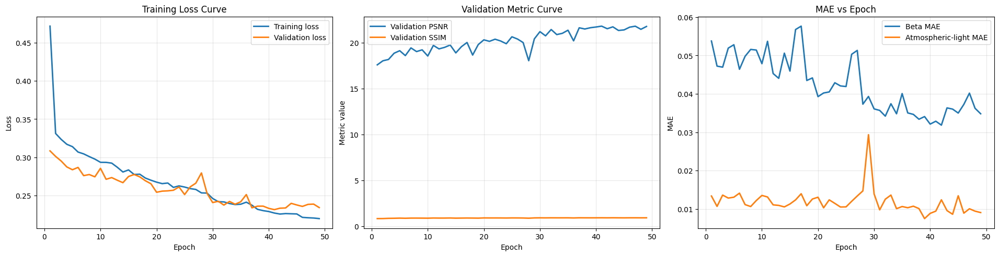

In [10]:
# Training diagnostics: loss, validation metrics, and MAE over epochs.
import matplotlib.pyplot as plt

if not joint_history["epoch"]:
    raise RuntimeError("No training history was recorded. Run the joint training cell first.")

epochs = joint_history["epoch"]
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8), constrained_layout=True)

axes[0].plot(epochs, joint_history["train_loss"], label="Training loss", linewidth=2)
axes[0].plot(epochs, joint_history["val_loss"], label="Validation loss", linewidth=2)
axes[0].set_title("Training Loss Curve")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(epochs, joint_history["val_psnr"], label="Validation PSNR", linewidth=2)
axes[1].plot(epochs, joint_history["val_ssim"], label="Validation SSIM", linewidth=2)
axes[1].set_title("Validation Metric Curve")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Metric value")
axes[1].grid(alpha=0.3)
axes[1].legend()

axes[2].plot(epochs, joint_history["val_beta_mae"], label="Beta MAE", linewidth=2)
axes[2].plot(epochs, joint_history["val_A_mae"], label="Atmospheric-light MAE", linewidth=2)
axes[2].set_title("MAE vs Epoch")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("MAE")
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.show()


## Clustering Diagnostics
The trained model predicts a dense beta map directly. Clustering below is used for analysis and presentation only; it does not alter inference.


In [11]:
print('Dense beta prediction is active. Cluster analysis is run later for diagnostics only.')


Dense beta prediction is active. Cluster analysis is run later for diagnostics only.


## Direct Dense Beta Prediction
The end-to-end model predicts a 56 x 56 beta map directly; there is no retrieval/refinement inference stage.


In [12]:
print('Using EndToEndPhysicsDehazer for direct beta prediction and final dehazing.')


Using EndToEndPhysicsDehazer for direct beta prediction and final dehazing.


## Final Dehazing Model
The final dehazing decoder is part of the end-to-end model and is optimized with beta, learned A, and physics losses.


In [13]:
print("Dehazing network is model.dehaze_net and has already been trained jointly.")
dehaze_model = model.dehaze_net


Dehazing network is model.dehaze_net and has already been trained jointly.


## Test Protocol: Three-Dataset Subjective and Objective Comparison
Evaluate `NHD_dataset`, `RESIDE`, and `reside-6k`. Each dataset must contain paired hazy and ground-truth haze-free images; the code feeds every hazy image through the method, computes haze-free outputs, and reports visual plus quantitative comparisons against GT.


In [14]:
def physics_dehaze_image(hazy, beta_hat, depth, A):
    transmission = np.exp(-beta_hat * depth)
    transmission = torch.tensor(transmission).float().unsqueeze(0).unsqueeze(0)
    transmission = F.interpolate(
        transmission,
        size=(cfg.IMAGE_SIZE, cfg.IMAGE_SIZE),
        mode="bilinear",
        align_corners=False,
    )
    transmission = transmission.squeeze().numpy()
    transmission = np.clip(transmission, 0.02, 1.0)
    clean = (hazy - A) / transmission[:, :, None] + A
    return np.clip(clean, 0.0, 1.0)


def mhcaf_dehaze_tensor(model, hazy_tensor):
    model.eval()
    with torch.no_grad():
        pred = model(hazy_tensor.unsqueeze(0).to(device)).squeeze(0).cpu()
    return pred.clamp(0, 1).permute(1, 2, 0).numpy()


def image_mae(pred, gt):
    return float(np.mean(np.abs(pred.astype(np.float32) - gt.astype(np.float32))))


def image_rmse(pred, gt):
    return float(np.sqrt(np.mean((pred.astype(np.float32) - gt.astype(np.float32)) ** 2)))


def dehaze_metrics(pred, gt):
    return {
        "PSNR": float(peak_signal_noise_ratio(gt, pred, data_range=1.0)),
        "SSIM": float(structural_similarity(gt, pred, channel_axis=-1, data_range=1.0)),
        "MAE": image_mae(pred, gt),
        "RMSE": image_rmse(pred, gt),
    }


def gradient_correlation(pred, gt):
    pred_dx = pred[:, 1:] - pred[:, :-1]
    gt_dx = gt[:, 1:] - gt[:, :-1]
    pred_dy = pred[1:, :] - pred[:-1, :]
    gt_dy = gt[1:, :] - gt[:-1, :]
    pred_grad = np.concatenate([pred_dx.flatten(), pred_dy.flatten()])
    gt_grad = np.concatenate([gt_dx.flatten(), gt_dy.flatten()])
    return safe_pearsonr(pred_grad, gt_grad)


# Step 1: choose datasets that contain paired hazy and ground-truth haze-free images.
reside_test_root = find_existing_test_folder([
    "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD/test",
    "/kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD",
    "/kaggle/input/datasets/surendrasudhakar/reside/RESIDE_NHD/test",
    "/kaggle/input/reside-dataset-1/RESIDE_NHD/test",
    "/kaggle/input/reside/RESIDE_NHD/test",
    "/kaggle/input/Reside/RESIDE_NHD/test",
    "/kaggle/input/datasets/reside-dataset-1/RESIDE_NHD/test",
])
reside6k_test_root = find_existing_test_folder([
    "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset/test",
    "/kaggle/input/datasets/rathlavathramesh/reside-6k-dataset",
    "/kaggle/input/datasets/surendrasudhakar/reside-6k-dataset/test",
    "/kaggle/input/reside-6k-dataset/test",
    "/kaggle/input/reside6k-dataset/test",
    "/kaggle/input/reside-6k/test",
    "/kaggle/input/datasets/reside-6k-dataset/test",
])

selected_test_datasets = {
    "NHD_dataset": test_dataset,
}
if reside_test_root is not None:
    reside_dataset = PairedHazyGTDataset("RESIDE", reside_test_root)
    if len(reside_dataset) > 0:
        selected_test_datasets["RESIDE"] = reside_dataset
    else:
        print(f"RESIDE folder found but no hazy/GT pairs matched: {reside_test_root}")
else:
    print("RESIDE test folder not found. Expected hazy/gt under /kaggle/input/datasets/rathlavathramesh/reside/RESIDE_NHD or its test subfolder.")

if reside6k_test_root is not None:
    reside6k_dataset = PairedHazyGTDataset("reside-6k", reside6k_test_root)
    if len(reside6k_dataset) > 0:
        selected_test_datasets["reside-6k"] = reside6k_dataset
    else:
        print(f"reside-6k folder found but no hazy/GT pairs matched: {reside6k_test_root}")
else:
    print("reside-6k test folder not found. Expected hazy/gt under /kaggle/input/datasets/rathlavathramesh/reside-6k-dataset or its test subfolder.")

print("Selected paired test datasets:")
for dataset_name, dataset in selected_test_datasets.items():
    print(f"  {dataset_name}: {len(dataset)} hazy/GT pairs")


def run_dehazing_test(model, dehaze_model, datasets, batch_size=None):
    """
    Step 2 and Step 3:
    - feed every hazy image from every selected dataset to the method,
    - estimate beta and compute the haze-free image,
    - compare computed haze-free image with GT subjectively/objectively.
    """
    model.eval()
    dehaze_model.eval()
    batch_size = batch_size or cfg.BATCH_SIZE

    records = []
    beta_records = []

    with torch.no_grad():
        for dataset_name, dataset in datasets.items():
            loader = DataLoader(
                dataset,
                batch_size=batch_size,
                shuffle=False,
                num_workers=cfg.NUM_WORKERS,
                pin_memory=torch.cuda.is_available(),
            )

            for batch in tqdm(loader, desc=f"Test {dataset_name}"):
                x = batch["hazy"].to(device)

                # Depth Anything V2 estimates the depth map for each hazy image at test time.
                predicted_depth = estimate_depth_batch(batch["hazy_vis"])
                out = model(x, predicted_depth, batch["hazy_vis"].to(device))

                beta_ret = out["beta_ret"].detach().cpu().numpy()
                beta_hat = out["beta_hat"].detach().cpu().numpy()
                A_hat = out["A_hat"].detach().cpu().numpy()
                beta_gt = batch["beta"].cpu().numpy()
                has_beta = batch["has_beta"].cpu().numpy().astype(bool)
                clean_hat_batch = out["clean_hat"].detach().cpu()

                for i in range(beta_hat.shape[0]):
                    hazy_img = batch["hazy_vis"][i].permute(1, 2, 0).numpy()
                    gt_img = batch["gt"][i].permute(1, 2, 0).numpy()
                    depth_img = predicted_depth[i, 0].detach().cpu().numpy()
                    A_img = A_hat[i]

                    # Haze-free image computed from estimated beta, learned A, and Depth Anything V2 depth.
                    physics_dehazed = physics_dehaze_image(hazy_img, beta_hat[i], depth_img, A_img)
                    mhcaf_dehazed = clean_hat_batch[i].permute(1, 2, 0).numpy()

                    physics_scores = dehaze_metrics(physics_dehazed, gt_img)
                    mhcaf_scores = dehaze_metrics(mhcaf_dehazed, gt_img)

                    record = {
                        "dataset": dataset_name,
                        "img_id": batch.get("img_id", [""] * beta_hat.shape[0])[i],
                        "strategy": batch.get("strategy", [""] * beta_hat.shape[0])[i],
                        "physics_psnr": physics_scores["PSNR"],
                        "physics_ssim": physics_scores["SSIM"],
                        "physics_mae": physics_scores["MAE"],
                        "physics_rmse": physics_scores["RMSE"],
                        "mhcaf_psnr": mhcaf_scores["PSNR"],
                        "mhcaf_ssim": mhcaf_scores["SSIM"],
                        "mhcaf_mae": mhcaf_scores["MAE"],
                        "mhcaf_rmse": mhcaf_scores["RMSE"],
                        "estimated_beta_mean": float(np.mean(beta_hat[i])),
                        "estimated_beta_min": float(np.min(beta_hat[i])),
                        "estimated_beta_max": float(np.max(beta_hat[i])),
                    }

                    if has_beta[i]:
                        m, r, c, r_two = beta_metrics(beta_hat[i], beta_gt[i])
                        g_corr = gradient_correlation(beta_hat[i], beta_gt[i])
                        record.update({
                            "beta_retrieved_mae": float(np.mean(np.abs(beta_ret[i] - beta_gt[i]))),
                            "beta_refined_mae": float(m),
                            "beta_rmse": float(r),
                            "beta_pearson": float(c),
                            "beta_gradient_corr": float(g_corr),
                            "beta_r2": float(r_two),
                        })
                        beta_records.append(record)
                    else:
                        record.update({
                            "beta_retrieved_mae": np.nan,
                            "beta_refined_mae": np.nan,
                            "beta_rmse": np.nan,
                            "beta_pearson": np.nan,
                            "beta_gradient_corr": np.nan,
                            "beta_r2": np.nan,
                        })

                    records.append(record)

    per_image_df = pd.DataFrame(records)
    summary_df = (
        per_image_df.groupby("dataset", as_index=False)
        .agg(
            Images=("img_id", "count"),
            Physics_PSNR=("physics_psnr", "mean"),
            Physics_SSIM=("physics_ssim", "mean"),
            Physics_MAE=("physics_mae", "mean"),
            Physics_RMSE=("physics_rmse", "mean"),
            MHCAFNetPP_PSNR=("mhcaf_psnr", "mean"),
            MHCAFNetPP_SSIM=("mhcaf_ssim", "mean"),
            MHCAFNetPP_MAE=("mhcaf_mae", "mean"),
            MHCAFNetPP_RMSE=("mhcaf_rmse", "mean"),
            Beta_Refined_MAE=("beta_refined_mae", "mean"),
            Beta_Pearson_Correlation=("beta_pearson", "mean"),
            Beta_Gradient_Correlation=("beta_gradient_corr", "mean"),
            Beta_R_Squared=("beta_r2", "mean"),
            Estimated_Beta_Mean=("estimated_beta_mean", "mean"),
        )
        .sort_values("dataset")
    )

    report = {
        "Datasets": list(datasets.keys()),
        "Total_Images": int(len(per_image_df)),
        "Physics_PSNR": float(per_image_df["physics_psnr"].mean()),
        "Physics_SSIM": float(per_image_df["physics_ssim"].mean()),
        "Physics_MAE": float(per_image_df["physics_mae"].mean()),
        "MHCAFNetPP_PSNR": float(per_image_df["mhcaf_psnr"].mean()),
        "MHCAFNetPP_SSIM": float(per_image_df["mhcaf_ssim"].mean()),
        "MHCAFNetPP_MAE": float(per_image_df["mhcaf_mae"].mean()),
        "NHD_Beta_Refined_MAE": float(per_image_df["beta_refined_mae"].mean(skipna=True)),
        "NHD_Beta_Pearson_Correlation": float(per_image_df["beta_pearson"].mean(skipna=True)),
        "NHD_Beta_Gradient_Correlation": float(per_image_df["beta_gradient_corr"].mean(skipna=True)),
        "NHD_Beta_R_Squared": float(per_image_df["beta_r2"].mean(skipna=True)),
    }
    return report, per_image_df, summary_df


report, per_image_results, dataset_summary = run_dehazing_test(
    model,
    dehaze_model,
    selected_test_datasets,
)

print("=" * 60)
print("Objective comparison: dehazing and beta-estimation metrics")
display(dataset_summary.style.format({
    "Physics_PSNR": "{:.4f}",
    "Physics_SSIM": "{:.4f}",
    "Physics_MAE": "{:.6f}",
    "Physics_RMSE": "{:.6f}",
    "MHCAFNetPP_PSNR": "{:.4f}",
    "MHCAFNetPP_SSIM": "{:.4f}",
    "MHCAFNetPP_MAE": "{:.6f}",
    "MHCAFNetPP_RMSE": "{:.6f}",
    "Beta_Refined_MAE": "{:.6f}",
    "Beta_Pearson_Correlation": "{:.6f}",
    "Beta_Gradient_Correlation": "{:.6f}",
    "Beta_R_Squared": "{:.6f}",
    "Estimated_Beta_Mean": "{:.6f}",
}))
print("=" * 60)
for k, v in report.items():
    print(f"{k:22s}: {v}")
print("=" * 60)

per_image_results.to_csv(os.path.join(cfg.OUT_DIR, "per_image_test_results.csv"), index=False)
dataset_summary.to_csv(os.path.join(cfg.OUT_DIR, "dataset_test_summary.csv"), index=False)
with open(os.path.join(cfg.OUT_DIR, "final_report.json"), "w") as f:
    json.dump(report, f, indent=2)


Selected paired test datasets:
  NHD_dataset: 70 hazy/GT pairs
  RESIDE: 200 hazy/GT pairs
  reside-6k: 1000 hazy/GT pairs


Test NHD_dataset:   0%|          | 0/9 [00:00<?, ?it/s]

Test RESIDE:   0%|          | 0/25 [00:00<?, ?it/s]

Test reside-6k:   0%|          | 0/125 [00:00<?, ?it/s]

Objective comparison: computed haze-free image vs GT haze-free image


,dataset,Images,Physics_PSNR,Physics_SSIM,Physics_MAE,Physics_RMSE,MHCAFNetPP_PSNR,MHCAFNetPP_SSIM,MHCAFNetPP_MAE,MHCAFNetPP_RMSE,Beta_Refined_MAE,Estimated_Beta_Mean
0,NHD_dataset,70,11.3098,0.6271,0.231506,0.278458,21.8524,0.8888,0.068560,0.092051,0.033397,0.173475
1,RESIDE,200,19.5006,0.8880,0.103693,0.123217,21.1354,0.8758,0.071245,0.094153,nan,0.159537
2,reside-6k,1000,14.6524,0.7688,0.174139,0.202370,20.4466,0.8418,0.077545,0.101075,nan,0.153909


Datasets              : ['NHD_dataset', 'RESIDE', 'reside-6k']
Total_Images          : 1270
Physics_PSNR          : 15.231646620545204
Physics_SSIM          : 0.779727467589491
Physics_MAE           : 0.16620704130687583
MHCAFNetPP_PSNR       : 20.632548433394298
MHCAFNetPP_SSIM       : 0.8497313230056462
MHCAFNetPP_MAE        : 0.07605747367864049
NHD_Beta_Refined_MAE  : 0.03339721151694123


## PSNR Comparison
Compare the physics reconstruction and final joint-dehazing PSNR on each evaluated dataset.


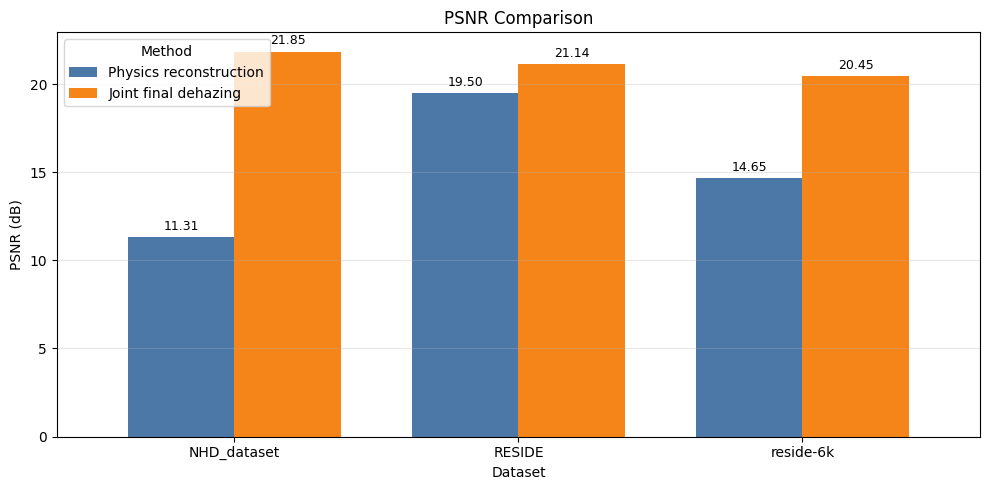

In [15]:
# PSNR comparison across each evaluated dataset.
psnr_columns = ["Physics_PSNR", "MHCAFNetPP_PSNR"]
psnr_labels = ["Physics reconstruction", "Joint final dehazing"]
psnr_data = dataset_summary.set_index("dataset")[psnr_columns]

ax = psnr_data.plot(
    kind="bar",
    figsize=(10, 5),
    width=0.75,
    color=["#4C78A8", "#F58518"],
)
ax.set_title("PSNR Comparison")
ax.set_xlabel("Dataset")
ax.set_ylabel("PSNR (dB)")
ax.set_xticklabels(psnr_data.index, rotation=0)
ax.legend(psnr_labels, title="Method")
ax.grid(axis="y", alpha=0.3)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=9)

plt.tight_layout()
plt.show()


## Subjective Visual Comparison
Show hazy input, GT haze-free image, predicted beta/depth diagnostics, and the computed haze-free output. This is the visual subjective comparison required for the selected test dataset(s).


dataset=NHD_dataset idx=14 beta_mae=0.09004 physics_psnr=11.51 physics_ssim=0.6247 mhcaf_psnr=20.88 mhcaf_ssim=0.8225
dataset=NHD_dataset idx=3 beta_mae=0.01161 physics_psnr=9.59 physics_ssim=0.5865 mhcaf_psnr=20.67 mhcaf_ssim=0.8540
dataset=NHD_dataset idx=35 beta_mae=0.00720 physics_psnr=12.60 physics_ssim=0.6408 mhcaf_psnr=26.59 mhcaf_ssim=0.9745
dataset=NHD_dataset idx=31 beta_mae=0.04684 physics_psnr=11.42 physics_ssim=0.5519 mhcaf_psnr=22.63 mhcaf_ssim=0.9278
dataset=NHD_dataset idx=28 beta_mae=0.00916 physics_psnr=11.49 physics_ssim=0.7174 mhcaf_psnr=17.55 mhcaf_ssim=0.7959


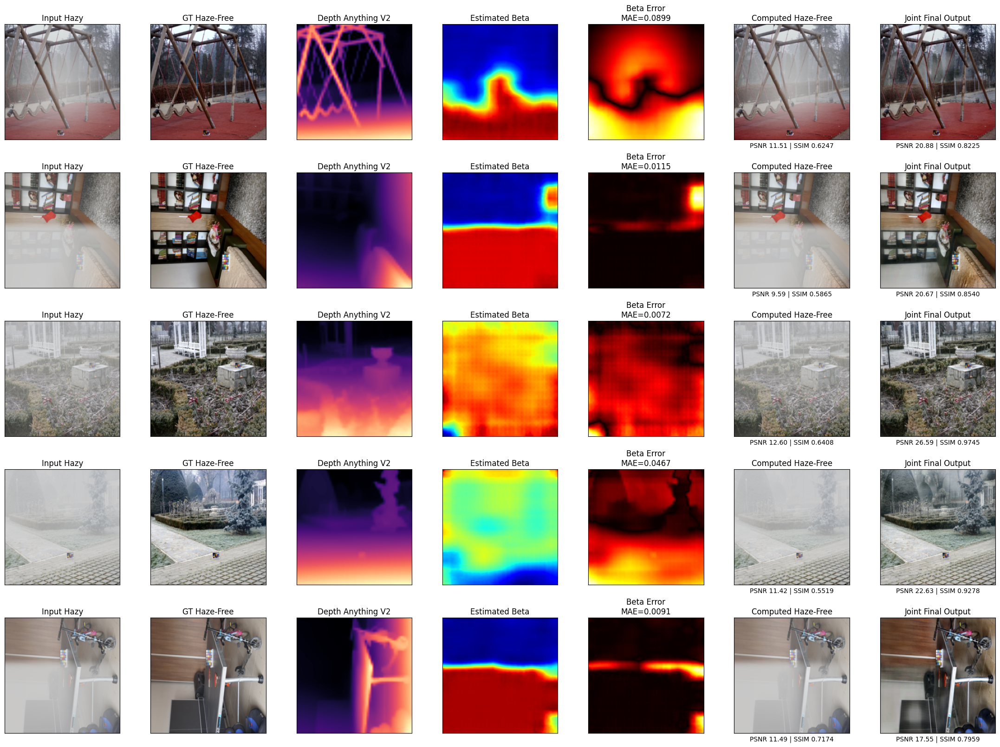

dataset=RESIDE idx=35 beta_gt=not_available physics_psnr=18.85 physics_ssim=0.9291 mhcaf_psnr=17.84 mhcaf_ssim=0.8576
dataset=RESIDE idx=188 beta_gt=not_available physics_psnr=26.10 physics_ssim=0.9626 mhcaf_psnr=19.62 mhcaf_ssim=0.8181
dataset=RESIDE idx=26 beta_gt=not_available physics_psnr=20.72 physics_ssim=0.9536 mhcaf_psnr=20.59 mhcaf_ssim=0.8703
dataset=RESIDE idx=173 beta_gt=not_available physics_psnr=22.93 physics_ssim=0.9601 mhcaf_psnr=17.81 mhcaf_ssim=0.8751
dataset=RESIDE idx=189 beta_gt=not_available physics_psnr=24.04 physics_ssim=0.9287 mhcaf_psnr=16.83 mhcaf_ssim=0.7723


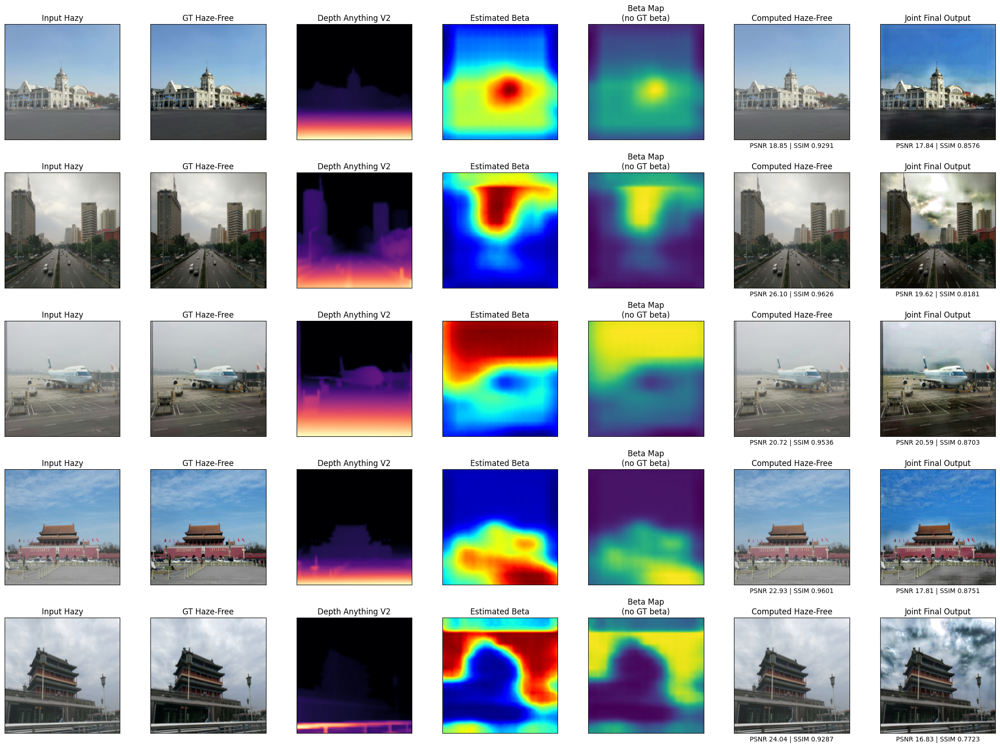

dataset=reside-6k idx=913 beta_gt=not_available physics_psnr=21.84 physics_ssim=0.9364 mhcaf_psnr=17.91 mhcaf_ssim=0.8750
dataset=reside-6k idx=558 beta_gt=not_available physics_psnr=13.76 physics_ssim=0.7910 mhcaf_psnr=20.86 mhcaf_ssim=0.8815
dataset=reside-6k idx=89 beta_gt=not_available physics_psnr=14.01 physics_ssim=0.7157 mhcaf_psnr=25.24 mhcaf_ssim=0.8894
dataset=reside-6k idx=604 beta_gt=not_available physics_psnr=15.57 physics_ssim=0.8045 mhcaf_psnr=21.48 mhcaf_ssim=0.8709
dataset=reside-6k idx=432 beta_gt=not_available physics_psnr=12.97 physics_ssim=0.7545 mhcaf_psnr=19.44 mhcaf_ssim=0.8400


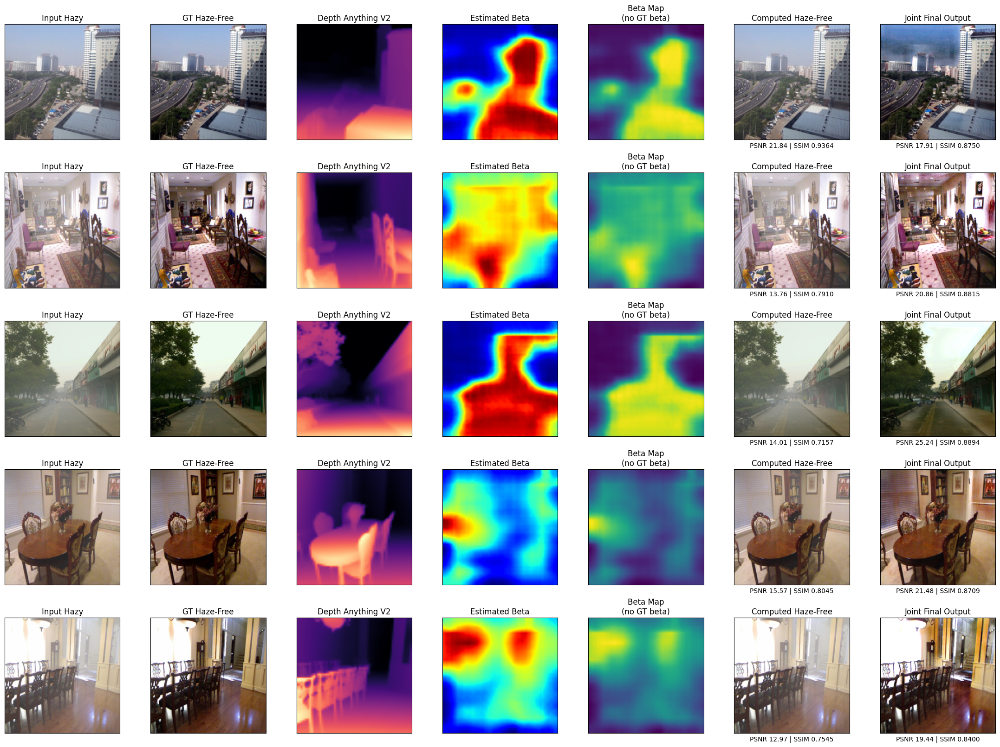

In [16]:
import matplotlib.pyplot as plt
import pandas as pd


def show_subjective_comparison(model, dehaze_model, dataset, dataset_name="NHD_dataset", n=5):
    model.eval()
    dehaze_model.eval()
    indices = random.sample(range(len(dataset)), min(n, len(dataset)))
    fig, ax = plt.subplots(len(indices), 7, figsize=(22, 3.2 * len(indices)), constrained_layout=True)
    if len(indices) == 1:
        ax = ax[None, :]

    for row, idx in enumerate(indices):
        sample = dataset[idx]
        hazy_np = sample["hazy_vis"].permute(1, 2, 0).numpy()
        depth = estimate_depth_tensor_from_hazy_vis(sample["hazy_vis"])

        with torch.no_grad():
            out = model(sample["hazy"].unsqueeze(0).to(device), depth, sample["hazy_vis"].unsqueeze(0).to(device))

        beta_hat = out["beta_hat"].squeeze().cpu().numpy()
        beta_gt = sample["beta"].numpy()
        has_beta = bool(sample.get("has_beta", False))
        depth_np = depth.squeeze().detach().cpu().numpy()

        gt_np = sample["gt"].permute(1, 2, 0).numpy()
        physics_dehazed = physics_dehaze_image(
            hazy_np,
            beta_hat,
            depth_np,
            out["A_hat"].squeeze().cpu().numpy(),
        )
        mhcaf_dehazed = out["clean_hat"].squeeze(0).cpu().permute(1, 2, 0).numpy()
        beta_hat_224 = cv2.resize(beta_hat, (cfg.IMAGE_SIZE, cfg.IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
        depth_224 = cv2.resize(depth_np, (cfg.IMAGE_SIZE, cfg.IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
        physics_scores = dehaze_metrics(physics_dehazed, gt_np)
        mhcaf_scores = dehaze_metrics(mhcaf_dehazed, gt_np)

        ax[row, 0].imshow(hazy_np)
        ax[row, 0].set_title("Input Hazy")
        ax[row, 1].imshow(gt_np)
        ax[row, 1].set_title("GT Haze-Free")
        ax[row, 2].imshow(depth_224, cmap="magma")
        ax[row, 2].set_title("Depth Anything V2")
        ax[row, 3].imshow(beta_hat_224, cmap="jet")
        ax[row, 3].set_title("Estimated Beta")

        if has_beta:
            beta_gt_224 = cv2.resize(beta_gt, (cfg.IMAGE_SIZE, cfg.IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
            err = np.abs(beta_gt_224 - beta_hat_224)
            ax[row, 4].imshow(err, cmap="hot")
            ax[row, 4].set_title(f"Beta Error\nMAE={err.mean():.4f}")
            beta_text = f" beta_mae={np.mean(np.abs(beta_gt - beta_hat)):.5f}"
        else:
            ax[row, 4].imshow(beta_hat_224, cmap="viridis")
            ax[row, 4].set_title("Beta Map\n(no GT beta)")
            beta_text = " beta_gt=not_available"

        ax[row, 5].imshow(physics_dehazed)
        ax[row, 5].set_title("Computed Haze-Free")
        ax[row, 5].set_xlabel(f"PSNR {physics_scores['PSNR']:.2f} | SSIM {physics_scores['SSIM']:.4f}")
        ax[row, 6].imshow(mhcaf_dehazed)
        ax[row, 6].set_title("Joint Final Output")
        ax[row, 6].set_xlabel(f"PSNR {mhcaf_scores['PSNR']:.2f} | SSIM {mhcaf_scores['SSIM']:.4f}")

        for col in range(7):
            ax[row, col].set_xticks([])
            ax[row, col].set_yticks([])

        print(
            f"dataset={dataset_name} idx={idx}{beta_text} "
            f"physics_psnr={physics_scores['PSNR']:.2f} physics_ssim={physics_scores['SSIM']:.4f} "
            f"mhcaf_psnr={mhcaf_scores['PSNR']:.2f} mhcaf_ssim={mhcaf_scores['SSIM']:.4f}"
        )

    plt.show()


def show_examples(model, dehaze_model, dataset, n=5):
    return show_subjective_comparison(model, dehaze_model, dataset, "NHD_dataset", n)


# Show 5 dehazed samples for each dataset: NHD_dataset, RESIDE, and reside-6k.
for dataset_name, dataset in selected_test_datasets.items():
    show_subjective_comparison(model, dehaze_model, dataset, dataset_name=dataset_name, n=5)


## Final Result Visualization
Display one final sample with beta comparison and final dehazing output.


,Metric,Value
0,Datasets,"NHD_dataset, RESIDE, reside-6k"
1,Total_Images,1270.000000
2,Physics_PSNR,15.231647
3,Physics_SSIM,0.779727
4,Physics_MAE,0.166207
5,MHCAFNetPP_PSNR,20.632548
6,MHCAFNetPP_SSIM,0.849731
7,MHCAFNetPP_MAE,0.076057
8,NHD_Beta_Refined_MAE,0.033397


Sample index: 0
Retrieved beta MAE  : 0.007181
Refined beta MAE    : 0.007181
Computed haze-free PSNR: 9.768777
Computed haze-free SSIM: 0.548654
Joint final PSNR    : 22.301675
Joint final SSIM    : 0.883563


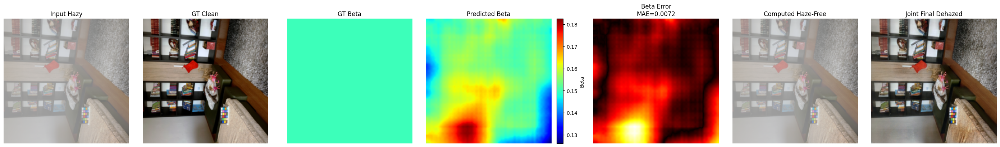

In [17]:
import matplotlib.pyplot as plt
import pandas as pd

def display_final_result(model, dehaze_model, dataset, sample_index=0):
    model.eval()
    dehaze_model.eval()

    metrics_df = pd.DataFrame(
        [
            {
                "Metric": k,
                "Value": ", ".join(v) if isinstance(v, list) else v,
            }
            for k, v in report.items()
        ]
    )

    def format_metric_value(value):
        if isinstance(value, (int, float, np.integer, np.floating)):
            return f"{float(value):.6f}"
        return str(value)

    display(metrics_df.style.format({"Value": format_metric_value}))

    sample = dataset[sample_index]
    hazy_np = sample["hazy_vis"].permute(1, 2, 0).numpy()
    depth = estimate_depth_tensor_from_hazy_vis(sample["hazy_vis"])

    with torch.no_grad():
        out = model(sample["hazy"].unsqueeze(0).to(device), depth, sample["hazy_vis"].unsqueeze(0).to(device))

    beta_hat = out["beta_hat"].squeeze().cpu().numpy()
    beta_ret = out["beta_ret"].squeeze().cpu().numpy()
    beta_gt = sample["beta"].numpy()

    gt_np = sample["gt"].permute(1, 2, 0).numpy()
    depth_np = depth.squeeze().detach().cpu().numpy()
    A_np = out["A_hat"].squeeze().cpu().numpy()

    physics_dehazed = physics_dehaze_image(hazy_np, beta_hat, depth_np, A_np)
    mhcaf_dehazed = out["clean_hat"].squeeze(0).cpu().permute(1, 2, 0).numpy()

    beta_gt_224 = cv2.resize(
        beta_gt,
        (cfg.IMAGE_SIZE, cfg.IMAGE_SIZE),
        interpolation=cv2.INTER_LINEAR,
    )
    beta_hat_224 = cv2.resize(
        beta_hat,
        (cfg.IMAGE_SIZE, cfg.IMAGE_SIZE),
        interpolation=cv2.INTER_LINEAR,
    )
    error_map = np.abs(beta_gt_224 - beta_hat_224)

    sample_metrics = {
        "Retrieved beta MAE": float(np.mean(np.abs(beta_gt - beta_ret))),
        "Refined beta MAE": float(np.mean(np.abs(beta_gt - beta_hat))),
        "Computed haze-free PSNR": float(peak_signal_noise_ratio(gt_np, physics_dehazed, data_range=1.0)),
        "Computed haze-free SSIM": float(structural_similarity(gt_np, physics_dehazed, channel_axis=-1, data_range=1.0)),
        "Joint final PSNR": float(peak_signal_noise_ratio(gt_np, mhcaf_dehazed, data_range=1.0)),
        "Joint final SSIM": float(structural_similarity(gt_np, mhcaf_dehazed, channel_axis=-1, data_range=1.0)),
    }

    print(f"Sample index: {sample_index}")
    for k, v in sample_metrics.items():
        print(f"{k:20s}: {v:.6f}")

    fig, ax = plt.subplots(1, 7, figsize=(28, 4), constrained_layout=True)

    ax[0].imshow(hazy_np)
    ax[0].set_title("Input Hazy")

    ax[1].imshow(gt_np)
    ax[1].set_title("GT Clean")

    beta_vmin = min(float(beta_gt_224.min()), float(beta_hat_224.min()))
    beta_vmax = max(float(beta_gt_224.max()), float(beta_hat_224.max()))

    im_gt = ax[2].imshow(beta_gt_224, cmap="jet", vmin=beta_vmin, vmax=beta_vmax)
    ax[2].set_title("GT Beta")

    im_hat = ax[3].imshow(beta_hat_224, cmap="jet", vmin=beta_vmin, vmax=beta_vmax)
    ax[3].set_title("Predicted Beta")

    ax[4].imshow(error_map, cmap="hot")
    ax[4].set_title(f"Beta Error\nMAE={error_map.mean():.4f}")

    ax[5].imshow(physics_dehazed)
    ax[5].set_title("Computed Haze-Free")

    ax[6].imshow(mhcaf_dehazed)
    ax[6].set_title("Joint Final Dehazed")

    for a in ax:
        a.axis("off")

    fig.colorbar(im_hat, ax=[ax[2], ax[3]], fraction=0.025, pad=0.02, label="Beta")
    plt.show()

    return metrics_df, mhcaf_dehazed


metrics_table, final_dehazed_image = display_final_result(
    model,
    dehaze_model,
    test_dataset,
    sample_index=0,
)


## Final Interpretation
The experiment uses a direct high-resolution beta decoder with Depth Anything V2 depth, learned atmospheric light, physics reconstruction, and a residual final dehazing decoder. The clustering plots are post-hoc diagnostics of the ground-truth beta-map regimes, not a codebook used at inference.


## Model Summary and Parameter Count
A compact, reproducible summary for the presentation.

In [18]:
from IPython.display import display

def count_parameters(module):
    return sum(p.numel() for p in module.parameters())

def model_summary_table(model):
    rows = []
    for name, module in model.named_children():
        rows.append({
            "Component": name,
            "Type": module.__class__.__name__,
            "Trainable parameters": count_parameters(module),
        })
    table = pd.DataFrame(rows)
    total = count_parameters(model)
    print(f"Model: {model.__class__.__name__}")
    print(f"Total trainable parameters: {total:,} ({total / 1e6:.2f} M)")
    print(f"Beta output: {cfg.BETA_GRID} x {cfg.BETA_GRID}; beta range: [{cfg.BETA_MIN}, {cfg.BETA_MAX}]")
    print("Pipeline: Hazy image -> ViT beta/A estimator -> depth-conditioned physics reconstruction -> residual dehazing decoder")
    display(table.style.format({"Trainable parameters": "{:,}"}))
    return table

model_components = model_summary_table(model)


Model: EndToEndPhysicsDehazer
Total trainable parameters: 23,981,687 (23.98 M)
Beta output: 56 x 56; beta range: [0.02, 2.0]
Pipeline: Hazy image -> ViT beta/A estimator -> depth-conditioned physics reconstruction -> residual dehazing decoder


,Component,Type,Trainable parameters
0,beta_a,HighResBetaAEstimator,"22,931,204"
1,dehaze_net,ResidualDehazeNet,"1,050,483"


## Beta-Map Cluster Analysis
Clusters reveal the distinct haze regimes in the ground-truth beta maps. This analysis is diagnostic only and does not modify the model.

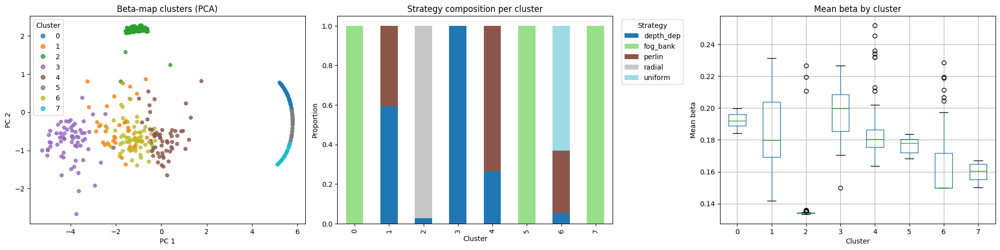

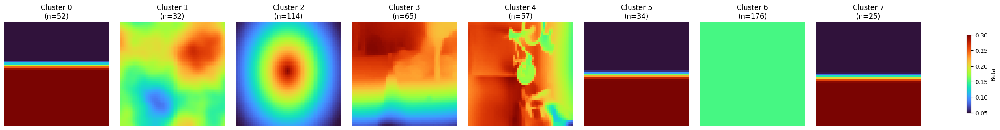

,Images,Mean_Beta
cluster,,
0,52,0.1922
1,32,0.1870
2,114,0.1365
3,65,0.1973
4,57,0.1865
5,34,0.1767
6,176,0.1611
7,25,0.1598


In [19]:
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
import matplotlib.pyplot as plt

def beta_cluster_analysis(dataset, n_clusters=8, max_samples=600, seed=42):
    if len(dataset) == 0:
        raise ValueError("Dataset is empty; check cfg.ROOT and dataset_index.json.")
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(dataset), size=min(max_samples, len(dataset)), replace=False)
    beta_maps = np.stack([dataset[int(i)]["beta"].numpy() for i in indices])
    labels_text = [dataset[int(i)]["strategy"] for i in indices]
    vectors = beta_maps.reshape(len(beta_maps), -1)
    # Centering makes the clusters reflect beta-map shape, rather than only mean haze level.
    vectors = vectors - vectors.mean(axis=1, keepdims=True)
    k = min(n_clusters, len(vectors))
    clusterer = MiniBatchKMeans(n_clusters=k, random_state=seed, batch_size=min(256, len(vectors)), n_init=10)
    clusters = clusterer.fit_predict(vectors)
    pca = PCA(n_components=2, random_state=seed)
    embedding = pca.fit_transform(vectors)
    info = pd.DataFrame({"cluster": clusters, "strategy": labels_text, "mean_beta": beta_maps.mean(axis=(1, 2))})

    fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)
    scatter = axes[0].scatter(embedding[:, 0], embedding[:, 1], c=clusters, cmap="tab10", s=24, alpha=.8)
    axes[0].set(title="Beta-map clusters (PCA)", xlabel="PC 1", ylabel="PC 2")
    axes[0].legend(*scatter.legend_elements(), title="Cluster", loc="best")
    pd.crosstab(info["cluster"], info["strategy"], normalize="index").plot(kind="bar", stacked=True, ax=axes[1], colormap="tab20")
    axes[1].set(title="Strategy composition per cluster", xlabel="Cluster", ylabel="Proportion")
    axes[1].legend(title="Strategy", bbox_to_anchor=(1.02, 1), loc="upper left")
    info.boxplot(column="mean_beta", by="cluster", ax=axes[2])
    axes[2].set(title="Mean beta by cluster", xlabel="Cluster", ylabel="Mean beta")
    plt.suptitle("")
    plt.show()

    fig, axes = plt.subplots(1, k, figsize=(3*k, 3), constrained_layout=True)
    axes = np.atleast_1d(axes)
    for c, ax in enumerate(axes):
        exemplar = beta_maps[np.where(clusters == c)[0][0]]
        im = ax.imshow(exemplar, cmap="turbo", vmin=beta_maps.min(), vmax=beta_maps.max())
        ax.set_title(f"Cluster {c}\n(n={(clusters == c).sum()})")
        ax.axis("off")
    fig.colorbar(im, ax=axes, shrink=.75, label="Beta")
    plt.show()
    return info, clusterer, pca

cluster_info, beta_clusterer, beta_pca = beta_cluster_analysis(train_dataset, n_clusters=8)
display(cluster_info.groupby("cluster").agg(Images=("cluster", "size"), Mean_Beta=("mean_beta", "mean")).round(4))


## Presentation Sample Export
Exports one complete, labelled panel: hazy input, GT clean image, GT beta, notebook-predicted beta, beta error, physics dehazing, and final joint dehazing.

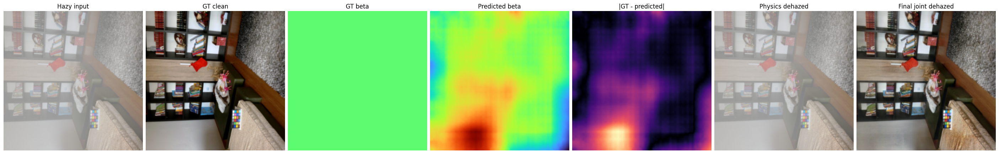

Saved panel: /kaggle/working/physics_graded_dehaze/presentation_sample_000.png


,beta_mae,physics_psnr,final_psnr,final_ssim
0,0.0072,9.7688,22.3017,0.8836


In [20]:
def export_presentation_sample(model, dataset, sample_index=0, output_dir=None):
    output_dir = output_dir or cfg.OUT_DIR
    os.makedirs(output_dir, exist_ok=True)
    model.eval()
    sample = dataset[sample_index]
    hazy = sample["hazy_vis"].permute(1, 2, 0).numpy()
    gt = sample["gt"].permute(1, 2, 0).numpy()
    beta_gt = sample["beta"].numpy()
    depth = estimate_depth_tensor_from_hazy_vis(sample["hazy_vis"])
    with torch.no_grad():
        out = model(sample["hazy"].unsqueeze(0).to(device), depth, sample["hazy_vis"].unsqueeze(0).to(device))
    beta_pred = out["beta_hat"].squeeze().detach().cpu().numpy()
    physics = physics_dehaze_image(hazy, beta_pred, depth.squeeze().detach().cpu().numpy(), out["A_hat"].squeeze().detach().cpu().numpy())
    final = out["clean_hat"].squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
    beta_gt_up = cv2.resize(beta_gt, (cfg.IMAGE_SIZE, cfg.IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
    beta_pred_up = cv2.resize(beta_pred, (cfg.IMAGE_SIZE, cfg.IMAGE_SIZE), interpolation=cv2.INTER_LINEAR)
    beta_error = np.abs(beta_gt_up - beta_pred_up)
    lo, hi = min(beta_gt_up.min(), beta_pred_up.min()), max(beta_gt_up.max(), beta_pred_up.max())
    panels = [(hazy, "Hazy input"), (gt, "GT clean"), (beta_gt_up, "GT beta"), (beta_pred_up, "Predicted beta"), (beta_error, "|GT - predicted|"), (physics, "Physics dehazed"), (final, "Final joint dehazed")]
    fig, axes = plt.subplots(1, 7, figsize=(28, 4.4), constrained_layout=True)
    for i, (image, title) in enumerate(panels):
        if 2 <= i <= 3:
            axes[i].imshow(image, cmap="turbo", vmin=lo, vmax=hi)
        elif i == 4:
            axes[i].imshow(image, cmap="magma")
        else:
            axes[i].imshow(image)
        axes[i].set_title(title)
        axes[i].axis("off")
    panel_path = os.path.join(output_dir, f"presentation_sample_{sample_index:03d}.png")
    fig.savefig(panel_path, dpi=220, bbox_inches="tight")
    plt.show()
    metrics = {"beta_mae": float(np.mean(np.abs(beta_gt-beta_pred))), "physics_psnr": dehaze_metrics(physics, gt)["PSNR"], "final_psnr": dehaze_metrics(final, gt)["PSNR"], "final_ssim": dehaze_metrics(final, gt)["SSIM"]}
    pd.DataFrame([metrics]).to_csv(os.path.join(output_dir, f"presentation_sample_{sample_index:03d}_metrics.csv"), index=False)
    print("Saved panel:", panel_path)
    display(pd.DataFrame([metrics]).round(4))
    return panel_path, metrics

presentation_panel_path, presentation_sample_metrics = export_presentation_sample(model, test_dataset, sample_index=0)
